# Missing data

Pupil and gaze data have gaps and bad samples for many reasons: the eye
tracker loses the pupil during a blink, the gaze leaves the screen, the
two eyes point to different places, or a part of the recording is simply
not part of the analysis. `pypillometry` keeps track of *why* a sample is
bad, and a *mask policy* decides which samples the analyses leave out.

This tutorial goes through these steps with a real recording. The
concepts are explained in the user guide ([Missing data](../user_guide/missing_data.rst)).

In [1]:
import pypillometry as pp
from pypillometry import u
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pp.logging_set_level("WARNING")

We use the example dataset `rlmw_002`: a 20-minute recording of both eyes
(pupil and gaze, 500 Hz) from a reinforcement-learning task. It is
downloaded from OSF on first use (see [Example datasets](example_datasets.ipynb)).

EyeData(rlmw_002, 39.9MiB):
 n                 : 597301
 sampling_rate     : 500.0
 eyes              : ['left', 'right']
 data              : ['left_x', 'left_y', 'left_pupil', 'right_x', 'right_y', 'right_pupil']
 nevents           : 1320
 experimental_setup: {'screen_resolution': (1280, 1024), 'physical_screen_size_mm': (300.0, 200.0), 'eye_to_screen_distance_mm': 600.0, 'camera_position': 'not set'}
 calibration       : not available
 duration_minutes  : 19.91
 start_min         : 0.0
 end_min           : 19.91
 params            : {}
 nblinks           : {}
 blinks            : {}
 glimpse           : EyeDataDict(vars=6,n=597301,shape=(597301,)): 
  left_x (float64): 655.6, 655.7, 655.0, 654.5, 655.0...
  left_y (float64): 599.9, 598.9, 597.6, 597.8, 597.8...
  left_pupil (float64): 1121.0, 1122.0, 1124.0, 1126.0, 1126.0...
  right_x (float64): 773.1, 773.8, 774.8, 776.3, 776.7...
  right_y (float64): 594.2, 593.9, 596.5, 597.4, 597.3...
  right_pupil (float64): 949.0, 951.0, 956.0, 959.0, 960.0...

 History:
 *
 └ reset_time()
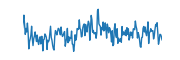
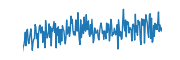
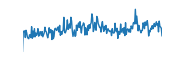
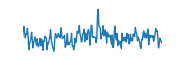
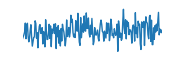
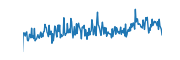

In [2]:
d = pp.get_example_data("rlmw_002", cache_dir="example_data")
d

## Missing samples in the raw data

Samples that the eye tracker did not record are NaN (Eyelink codes them as
0; they are converted to NaN when the data are read). NaN is the only kind
of missing data that is stored in the values themselves.
`d.mask(eye, variable)` returns `True` for each unusable sample:

In [3]:
for key in d.data:
    print(f"{key:12s} {np.isnan(d.data[key]).mean():6.2%} NaN, "
          f"{d.mask(key).mean():6.2%} masked")

left_x        3.13% NaN,  3.13% masked
left_y        3.13% NaN,  3.13% masked
left_pupil    3.13% NaN,  3.13% masked
right_x       2.07% NaN,  2.07% masked
right_y       2.07% NaN,  2.07% masked
right_pupil   2.07% NaN,  2.07% masked


## Marking bad samples: mask layers

The detection methods do not change the values. They mark the samples
they find in a *mask layer* of the channels they check:

- `d.pupil.blinks_detect()` sets the `"blink"` layer of the pupil;
- `d.gaze.mask_offscreen()` sets the `"offscreen"` layer of x and y (it
  needs the screen size, which is stored with this dataset);
- `d.gaze.mask_divergences()` sets the `"divergence"` layer of x and y of
  both eyes.

In [4]:
d.pupil.blinks_detect()
d.gaze.mask_offscreen()
d.gaze.mask_divergences()
d.data.layer_names

['blink', 'offscreen', 'divergence']

To see what is masked where, we write a small helper that shows, for each
channel, the percentage of samples that are NaN, the percentage in each
layer, and the percentage that is masked under the `"default"` and the
`"strict"` policy (explained below). A sample can be in several layers at
once (a blink is usually also NaN), so the columns do not add up.

In [5]:
def layer_table(d):
    rows = {}
    for key in d.data:
        row = {"NaN": np.isnan(d.data[key]).mean()}
        for name in d.data.layer_names:
            if name == "excluded":   # one layer for the whole recording
                row[name] = d.data.get_rec_layer(name).mean()
            else:
                row[name] = d.data.get_layer(key, name).mean()
        row["masked (default)"] = d.mask(key).mean()
        row["masked (strict)"] = d.mask(key, policy="strict").mean()
        rows[key] = row
    return (100 * pd.DataFrame(rows).T).round(2)

layer_table(d)

,NaN,blink,offscreen,divergence,masked (default),masked (strict)
left_x,3.13,0.00,0.97,0.97,4.86,4.86
left_y,3.13,0.00,0.97,0.97,4.86,4.86
left_pupil,3.13,5.84,0.00,0.00,5.84,5.84
right_x,2.07,0.00,1.04,0.97,4.06,4.06
right_y,2.07,0.00,1.04,0.97,4.06,4.06
right_pupil,2.07,4.08,0.00,0.00,4.09,4.09


Each layer belongs to the channels it was detected on: blinks are on the
pupil only, off-screen samples and divergences on x and y only. The gaze
channels are still masked during blinks, because the eye tracker records
no gaze then (NaN).

The layers can be read back as `Intervals` (in ms), one per channel:

In [6]:
blinks = d.get_blinks()
blinks["left_pupil"]

Intervals 'left_pupil_blinks' | 321 intervals (total duration: 69762.00 ms), 217.33 ms +/- 136.83 ms, [22.00 ms, 984.00 ms]

In [7]:
d.get_layer_intervals("offscreen", variables="x")

{'left_x': Intervals 'left_x_offscreen' | 383 intervals (total duration: 11582.00 ms), 30.24 ms +/- 79.67 ms, [2.00 ms, 544.00 ms],
 'right_x': Intervals 'right_x_offscreen' | 405 intervals (total duration: 12448.00 ms), 30.74 ms +/- 77.91 ms, [2.00 ms, 542.00 ms]}

With these, we can draw where each layer is set in each channel, here for
30 seconds of the recording (the grey bars are NaN samples).
`d.plot.plot_masked()` gives a similar overview of the masked stretches
for the whole recording.

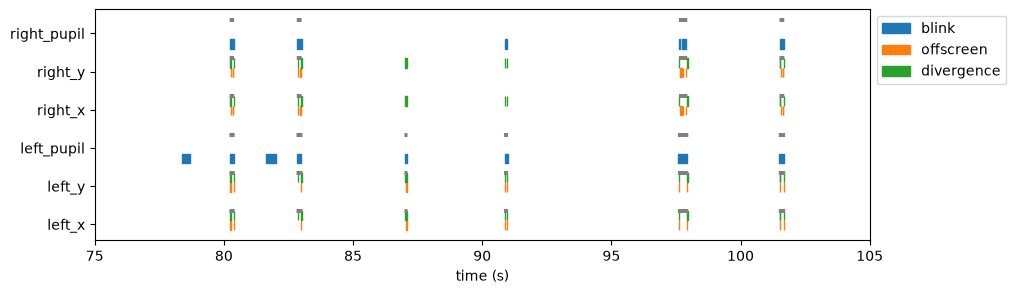

In [8]:
def plot_layers(d, start, end, layers=("blink", "offscreen", "divergence")):
    fig, ax = plt.subplots(figsize=(10, 3))
    keys = list(d.data)
    sel = (d.tx >= start) & (d.tx < end)
    for row, key in enumerate(keys):
        for col, name in enumerate(layers):
            runs = d.get_layer_intervals(name, units="sec")[key]
            ax.broken_barh([(on, off - on) for on, off in runs if off > start / 1000 and on < end / 1000],
                           (row - 0.4 + 0.25 * col, 0.25), color=f"C{col}",
                           label=name if row == 0 else None)
        nan = np.isnan(d.data[key][sel])
        ax.scatter(d.tx[sel][nan] / 1000, np.full(nan.sum(), row + 0.35), marker="|", color="0.5", s=10)
    ax.set_yticks(range(len(keys)), keys)
    ax.set_xlim(start / 1000, end / 1000)
    ax.set_xlabel("time (s)")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))

plot_layers(d, 75_000, 105_000)

Most blinks are NaN in all channels, and the gaze around them is often
off the screen or divergent as the eyelid closes. Some blinks (here at
78.5 s and 82 s in the left eye) were found from the velocity of the
pupil size although no sample is missing: the layer records the detection,
not only the gaps.

## Re-running a detector replaces its layer

Each detector only writes its own layer and replaces it when it runs
again. Trying other parameters therefore never adds up masks from earlier
runs, and `clear_layer()` undoes a detection:

In [9]:
def nblinks(d):
    return {ch: stats["n"] for ch, stats in d.blink_stats().items()}

n_default = nblinks(d)
d.pupil.blinks_detect(vel_onset=-20, vel_offset=20)   # less sensitive
n_other = nblinks(d)
d.pupil.blinks_detect()                               # back to the defaults
print(n_default, n_other, nblinks(d), sep="\n")

{'left_pupil': 321, 'right_pupil': 307}
{'left_pupil': 253, 'right_pupil': 231}
{'left_pupil': 321, 'right_pupil': 307}


In [10]:
d2 = d.clear_layer("divergence", inplace=False)
d2.data.get_layer("left_x", "divergence").sum()

np.int64(0)

## Excluded periods

Some parts of a recording are not part of the analysis, e.g. the time
before the task starts or breaks. They are not *missing* data: blink
detection and the quality report ignore them instead of counting them as
gaps. `exclude_intervals()` and `keep_intervals()` store them in the
recording-wide `"excluded"` layer, which masks all channels, including
channels added later. Here we keep the time from 1 s before the first event
to 3 s after the last one:

In [11]:
first, last = d.events.onsets[0], d.events.onsets[-1]
d.keep_intervals([(first - 1000, last + 3000)])
d.get_excluded("sec")

Intervals 'excluded' | 1 intervals (total duration: 4.18 sec), 4.18 sec +/- 0.00 sec, [4.18 sec, 4.18 sec]

In [12]:
layer_table(d)

,NaN,blink,offscreen,divergence,excluded,masked (default),masked (strict)
left_x,3.13,0.00,0.97,0.97,0.35,5.13,5.13
left_y,3.13,0.00,0.97,0.97,0.35,5.13,5.13
left_pupil,3.13,5.84,0.00,0.00,0.35,6.19,6.19
right_x,2.07,0.00,1.04,0.97,0.35,4.33,4.33
right_y,2.07,0.00,1.04,0.97,0.35,4.33,4.33
right_pupil,2.07,4.08,0.00,0.00,0.35,4.44,4.44


## Mask policies

A *mask policy* decides which layers make a sample unusable. All analysis
and processing methods take a `policy=` argument; there are three
predefined policies:

| policy | masked samples |
|---|---|
| `"default"` | NaN, blinks, off-screen, divergences, user masks, excluded periods; **interpolated samples are used** |
| `"strict"` | the same, and interpolated samples |
| `"raw"` | nothing, not even NaN |

`d.mask()` gives the mask, `d.values()` the values with NaN where the
mask is set, and `d["left_pupil"]` a numpy masked array under the default
policy:

In [13]:
for policy in ["default", "strict", "raw"]:
    print(f"{policy:8s} {d.mask('left_pupil', policy=policy).mean():6.2%} masked")

default   6.19% masked
strict    6.19% masked
raw       0.00% masked


In [14]:
x = d["left_pupil"]
type(x).__name__, x.mask.mean().round(4)

('MaskedArray', np.float64(0.0619))

A policy can also be a list of layers (NaN is always included), e.g. to
look only at the blinks:

In [15]:
d.mask("left_pupil", policy=["blink"]).mean()

np.float64(0.0584495924165538)

## Interpolating blinks

`d.pupil.blinks_interpolate()` replaces the pupil size during the blinks
by a smooth curve. The interpolated samples get the `"interpolated"`
layer; the `"blink"` layer stays, so it is always known which samples
were reconstructed. Under the default policy, the interpolated samples are
used, under the strict policy they are not:

In [16]:
d.pupil.blinks_interpolate()
layer_table(d)

,NaN,blink,offscreen,divergence,excluded,interpolated,masked (default),masked (strict)
left_x,3.13,0.00,0.97,0.97,0.35,0.00,5.13,5.13
left_y,3.13,0.00,0.97,0.97,0.35,0.00,5.13,5.13
left_pupil,0.00,5.84,0.00,0.00,0.35,7.49,0.35,7.84
right_x,2.07,0.00,1.04,0.97,0.35,0.00,4.33,4.33
right_y,2.07,0.00,1.04,0.97,0.35,0.00,4.33,4.33
right_pupil,0.00,4.08,0.00,0.00,0.35,5.66,0.35,6.01


After interpolation, no pupil sample is NaN any more, and the pupil is
only masked in the excluded periods (default policy). The strict policy
still masks the interpolated samples. Note that the interpolated stretches
are a bit longer than the blinks: the method extends each blink by a
margin, because the samples next to a blink are distorted as well.

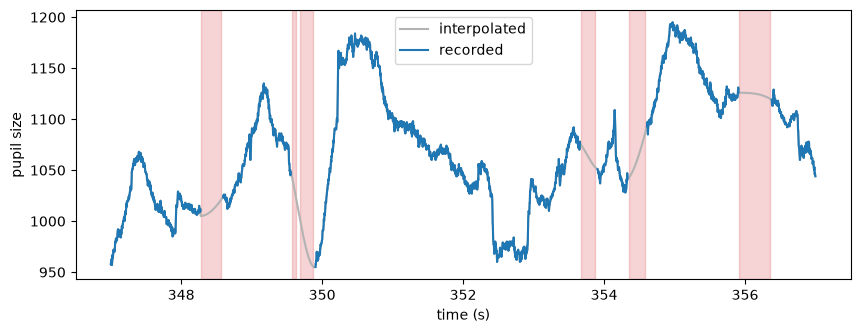

In [17]:
fig, ax = plt.subplots(figsize=(10, 3.5))
sel = (d.tx > 347_000) & (d.tx < 357_000)
t = d.tx[sel] / 1000
ax.plot(t, d.get_values("left_pupil", policy="raw")[sel], color="0.7", label="interpolated")
ax.plot(t, d.get_values("left_pupil", policy="strict")[sel], color="C0", label="recorded")
for on, off in d.get_blinks(eyes="left", variables="pupil", units="sec")["left_pupil"]:
    if t[0] < on < t[-1]:
        ax.axvspan(on, off, color="C3", alpha=0.2)
ax.set_xlabel("time (s)"); ax.set_ylabel("pupil size"); ax.legend();

The red stretches are the detected blinks, the grey line the values that
the default policy uses there.

## Pupil samples during off-screen gaze

The off-screen and divergence layers mask only the gaze channels. Whether
the pupil size is still valid when the gaze is off the screen depends on
the setup; to mask the pupil there as well, copy the off-screen periods to
the pupil with `mask_intervals()`. They go into the pupil's `"user"`
layer:

In [18]:
d3 = d.copy()
off = d3.get_layer_intervals("offscreen", variables="x")
d3.mask_intervals({"left_pupil": off["left_x"], "right_pupil": off["right_x"]})
layer_table(d3).loc[["left_pupil", "right_pupil"]]

,NaN,blink,offscreen,divergence,excluded,interpolated,user,masked (default),masked (strict)
left_pupil,0.0,5.84,0.0,0.0,0.35,7.49,0.97,1.04,8.53
right_pupil,0.0,4.08,0.0,0.0,0.35,5.66,1.04,1.04,6.70


The pupil is now in the `"user"` layer for about 1% of the samples, but
the default policy masks fewer of them. The reason: under the default
policy, an **interpolated sample is always usable**, whatever other layer
of the channel is set and in whichever order the layers were set
(only excluded periods mask it). Off-screen periods that fall into an
interpolated blink therefore stay usable:

In [19]:
user = d3.data.get_layer("left_pupil", "user")
interp = d3.data.get_layer("left_pupil", "interpolated")
print(f"user layer: {user.mean():.2%}, of that interpolated: {(user & interp).mean():.2%}")

user layer: 0.97%, of that interpolated: 0.28%


To leave these samples out as well, use the strict policy (which leaves
out all interpolated samples), or a policy that lists the layers to mask
without the exception for interpolated samples, e.g.
`policy=["user", "excluded"]`.

## Filtering

The filters read the usable samples only. Unusable samples are bridged
linearly for the filter and keep their values, so neither blinks nor
excluded periods leak into their neighbours:

In [20]:
before = d.data["left_pupil"].copy()
d.pupil.lowpass_filter(cutoff=4)
masked = d.mask("left_pupil")
print("masked samples unchanged:", np.array_equal(before[masked], d.data["left_pupil"][masked]))
print("usable samples filtered: ", not np.allclose(before[~masked], d.data["left_pupil"][~masked]))

masked samples unchanged: True
usable samples filtered:  True


## Event-related analyses

Segments around events (`get_segments()`) and statistics per event
(`stat_per_event()`) use the policy as well. With the default policy, the
interpolated samples are part of each trial; with the strict policy, they
are masked. This lets us find the trials that consist mostly of
reconstructed data:

SegmentedEyeData(S_): 300 segments x 1500 time points (-500 to 2498 ms, 500 Hz)
  channels: left_pupil (0.0% missing)
  epochs: Epochs 'S_' | 300 epochs, window (-500, 2500) ms
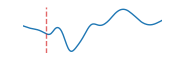

In [21]:
stim = d.get_epochs("S_", window=(-500, 2500) * u.ms)
seg = d.get_segments(stim, "left_pupil")
seg_strict = d.get_segments(stim, "left_pupil", policy="strict")
seg

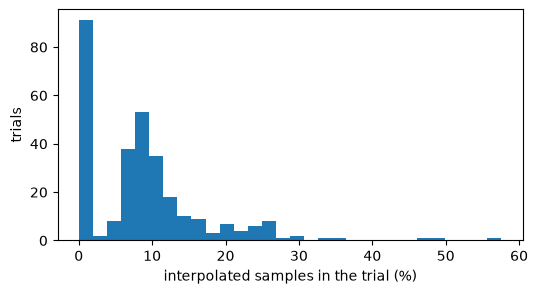

In [22]:
recon = np.ma.getmaskarray(seg_strict["left_pupil"]).mean(axis=0)   # one value per trial
fig, ax = plt.subplots(figsize=(6, 3))
ax.hist(100 * recon, bins=30)
ax.set_xlabel("interpolated samples in the trial (%)"); ax.set_ylabel("trials");

`Epochs.keep()` selects the trials to keep, e.g. those with less than 25%
interpolated samples:

In [23]:
good = stim.keep(recon < 0.25)
print(len(stim), "trials,", len(good), "with less than 25% interpolated samples")

300 trials, 284 with less than 25% interpolated samples


In [24]:
mean_default = d.stat_per_event(stim, variables="pupil")["left_pupil"]
mean_strict = d.stat_per_event(stim, variables="pupil", policy="strict")["left_pupil"]
diff = np.abs(np.asarray(mean_default) - np.asarray(mean_strict))
print(f"largest difference in a trial mean: {np.nanmax(diff):.1f} "
      f"(median {np.nanmedian(diff):.2f})")

largest difference in a trial mean: 48.1 (median 3.13)


## Downsampling

`downsample()` averages the usable samples in each new sampling interval.
The layers are carried over: a new sample is in a layer if the layer
covers more than half of its interval. The proportion of samples in each
layer therefore stays about the same:

In [25]:
dd = d.downsample(50, inplace=False)
pd.DataFrame({"500 Hz": layer_table(d).loc["left_pupil"],
              "50 Hz": layer_table(dd).loc["left_pupil"]})

,500 Hz,50 Hz
NaN,0.00,0.00
blink,5.84,5.78
offscreen,0.00,0.00
divergence,0.00,0.00
excluded,0.35,0.35
interpolated,7.49,7.45
masked (default),0.35,0.35
masked (strict),7.84,7.80


## Combining the eyes

`d.pupil.merge_eyes()` computes `mean_pupil` from the usable samples of
both eyes, recorded samples first: where one eye was interpolated and the
other one recorded, the recorded value is used (after the offset
correction). The merged channel gets the layers that the eyes used for a
sample have in common: it is `"interpolated"` only where both eyes were
interpolated, and it is masked where neither eye is usable:

In [26]:
dm = d.pupil.merge_eyes(inplace=False)
layer_table(dm).loc[["left_pupil", "right_pupil", "mean_pupil"]]

,NaN,blink,offscreen,divergence,excluded,interpolated,masked (default),masked (strict)
left_pupil,0.0,5.84,0.0,0.0,0.35,7.49,0.35,7.84
right_pupil,0.0,4.08,0.0,0.0,0.35,5.66,0.35,6.01
mean_pupil,0.0,3.33,0.0,0.0,0.35,4.84,0.35,5.19


Because `mean_pupil` keeps the `"interpolated"` layer where both eyes
were interpolated, the strict policy leaves these samples out in the
following steps (column "masked (strict)"). Merging with
`policy="strict"` gives the same channel here:

In [27]:
dm = d.pupil.merge_eyes(policy="strict", inplace=False)
layer_table(dm).loc[["mean_pupil"]]

,NaN,blink,offscreen,divergence,excluded,interpolated,masked (default),masked (strict)
mean_pupil,0.0,3.33,0.0,0.0,0.35,4.84,0.35,5.19


## Missing data in the quality report

The quality report counts missing data in the *values* (NaN) and reports
the mask layers in its "Artifacts" section; excluded periods are left out
of all measures. Interpolation fills the NaN samples, so after
preprocessing the pupil shows no missing data any more. Run the report on
the raw data to judge the recording, and after preprocessing to see what
was masked and interpolated:

In [28]:
raw = pp.get_example_data("rlmw_002", cache_dir="example_data")
raw.keep_intervals([(first - 1000, last + 3000)])
keys = ["pupil.left.missing_pct", "pupil.left.dropout_rate", "gaze.left.missing_pct",
        "artifacts.left.pupil_masked_pct", "artifacts.left.gaze_masked_pct"]
pd.DataFrame({"raw": pd.Series(raw.quality_report().to_dict(flat=True)).reindex(keys),
              "preprocessed": pd.Series(d.quality_report().to_dict(flat=True)).reindex(keys)})

,raw,preprocessed
pupil.left.missing_pct,3.138882,0.0
pupil.left.dropout_rate,15.423076,0.0
gaze.left.missing_pct,3.138882,3.138882
artifacts.left.pupil_masked_pct,NaN,0.0
artifacts.left.gaze_masked_pct,NaN,4.795098


In [29]:
d.quality_report()

Quality report: rlmw_002 (EyeData)
Overall: GOOD

Recording
  duration       19.9 min
  included       19.8 min
  sampling rate    500 Hz
  samples          597301
  events             1320
  time gaps             0

Pupil                left        right
  missing data       0.0% good    0.0% good
  dropouts         0 /min good  0 /min good
  longest dropout     0 s good     0 s good
  noise            0.027% good  0.032% good
  noise (SD)        0.283        0.286
  jumps            0 /min good  0 /min good

Gaze                  left            right
  missing data        3.1% good        2.1% good
  off-screen          1.0% good        1.1% good
  precision     0.0185 deg good  0.0186 deg good

Binocular            left/right
  pupil correlation       0.943 good
  gaze disparity      0.418 deg good

Blinks                 left           right
  number                321             307
  blink rate      16.2 /min good  15.5 /min good
  mean duration      217 ms          159 ms
  time in blinks       5.9% good       4.1% good
  long (>500 ms)         14              10

Artifacts             left       right
  pupil masked        0.0% good   0.0% good
  interpolated        7.5% good   5.7% good
  gaze masked         4.8% good   4.0% good
  masked off-screen  0.97%        1.0%
  masked divergence  0.89%       0.89%
  other artifacts     0.0%        0.0%

## Saving

The layers are saved with the object (`write_file()`, `write_file()`),
so a saved dataset keeps the information on why each sample was masked:

In [30]:
import tempfile, os
fname = os.path.join(tempfile.mkdtemp(), "rlmw_002.pypil")
d.write_file(fname)
d_loaded = pp.EyeData.from_file(fname)
d_loaded.data.layer_names, np.array_equal(d_loaded.mask("left_pupil", policy="strict"),
                                          d.mask("left_pupil", policy="strict"))

(['blink', 'offscreen', 'divergence', 'excluded', 'interpolated'], True)

## Summary

- Samples the eye tracker did not record are NaN in the values. All other
  reasons are mask layers, which record *why* a sample is bad. Each
  detector writes its own layer on the channels it checks and replaces it
  when it runs again.
- Excluded periods are one layer for the whole recording; they mask every
  channel but are not counted as missing data.
- The mask policy (`"default"`, `"strict"`, `"raw"`, or a list of layers)
  decides which samples the analyses use. By default, interpolated
  samples are used, even where another layer is set.
- To mask the pupil where the gaze is bad, copy the gaze layers with
  `mask_intervals()`.
- `merge_eyes()` prefers recorded samples and keeps the layers the eyes
  have in common, so `policy="strict"` still leaves out samples that were
  interpolated in both eyes.